# 02 · Modelado y evaluación

**Proyecto:** Predicción temprana de acreditación en el Programa de Terminalidad de Educación Profesional Secundaria (TEPS) – Tierra del Fuego

**Autora:** Gabriela Soledad Bacchiani

**Problema:** Anticipar, con la información disponible al **1° cierre de notas parcial**, qué estudiantes **no acreditarán** el nivel, para que la coordinadora pueda acompañarlos a tiempo y favorecer la acreditación del nivel.

**Datos:** Registros estudiante-nivel de 2025-2026, construidos a partir de las planillas de asistencia (con la nómina de cada cuatrimestre) y de las versiones de las planillas de calificaciones al corte de la 1° nota parcial. El detalle está en [`docs/dataset.md`](../docs/dataset.md) y el análisis exploratorio en [`01-gsb-eda-preprocesamiento.ipynb`](01-gsb-eda-preprocesamiento.ipynb).

**Esta notebook:**

1. Define cómo se evalúa (validación cruzada por estudiante dentro del entrenamiento).
2. Entrena dos modelos simples: **regresión logística** y **árbol de decisión**, y los compara con un modelo de referencia.
3. Ajusta sus hiperparámetros con validación cruzada.
4. Evalúa el modelo elegido **una sola vez** en la prueba (1° cuatrimestre 2026).
5. Interpreta el modelo, revisa su desempeño por grupos y muestra qué pasaba con las planillas finales (fuga de datos).
6. Aplica el modelo a los estudiantes que cursan nivel 4 actualmente.

La clase de interés es **`no_acredita = 1`**: todas las métricas (precision, recall, F1) se refieren a ella.

## 1. Librerías y datos

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

sns.set_theme(style="whitegrid", palette="Set2")
SEMILLA = 42
import os


def encontrar_raiz():
    """Busca la carpeta del proyecto (la que tiene teps/dataset.py y data/), desde donde se ejecute la notebook."""
    inicio = [Path.cwd()]
    if os.environ.get("JPY_SESSION_NAME"):              # ruta de la notebook en JupyterLab
        inicio.insert(0, Path(os.environ["JPY_SESSION_NAME"]).parent)
    for base in inicio:
        for carpeta in [base, *base.parents]:            # hacia arriba
            if (carpeta / "teps" / "dataset.py").exists() and (carpeta / "data").is_dir():
                return carpeta
    for nivel in range(1, 5):                            # hacia abajo, hasta 4 carpetas
        for marca in Path.cwd().glob("/".join(["*"] * nivel) + "/teps/dataset.py"):
            if (marca.parent.parent / "data").is_dir():
                return marca.parent.parent
    raise FileNotFoundError("No se encontró la carpeta del proyecto. Abrí la notebook desde la carpeta del repositorio.")


RAIZ = encontrar_raiz()
print("Carpeta del proyecto:", RAIZ.name)
DATOS = RAIZ / "data" / "processed"
FIGURAS = RAIZ / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

objetivo = "no_acredita"
if (DATOS / "dataset_real.csv").exists():
    completo = pd.read_csv(DATOS / "dataset_real.csv")
    origen = "real"
else:
    completo = pd.read_csv(DATOS / "dataset_sintetico.csv")
    origen = "sintético"
    print("ATENCIÓN: datos sintéticos. Sirven solo para comprobar que el código corre; los resultados no son válidos.")

# Misma separación que en la notebook 01: cohortes ordenadas y sin personas repetidas
modelo = completo[completo.motivo_exclusion.isna()].copy()
es_prueba = (modelo.anio == 2026) & (modelo.cuatri == 1)
ids_prueba = set(modelo.loc[es_prueba, "id_estudiante"])
train = modelo[(modelo.anio == 2025) & ~modelo.id_estudiante.isin(ids_prueba)].copy()
test = modelo[es_prueba].copy()
en_curso = completo[completo.motivo_exclusion == "en curso (sin resultado todavía)"].copy()
print(f"Datos: {origen} | entrenamiento: {len(train)} ({int(train[objetivo].sum())} no acreditan) | "
      f"prueba: {len(test)} ({int(test[objetivo].sum())} no acreditan) | en curso: {len(en_curso)}")

Carpeta del proyecto: prediccion-acreditacion-teps
Datos: real | entrenamiento: 75 (39 no acreditan) | prueba: 22 (4 no acreditan) | en curso: 19


## 2. Variables y preprocesamiento

Se usan las variables seleccionadas en la notebook 01 **con el conjunto de entrenamiento** (se eliminaron las constantes y las redundantes). El preprocesamiento (imputación, one-hot encoding y escalado) va **dentro del pipeline**: en cada pliegue de la validación cruzada se ajusta solo con los datos de ese pliegue, así que no se filtra información de los datos de validación.

In [2]:
num_vars = ["clases_dictadas_corte", "pct_asistencia", "pct_asist_electronica", "pct_ausente_con_aviso",
            "licencias_medicas", "pct_tps_entregados", "promedio_tps", "promedio_1p", "materias_1p_menor6"]
cat_vars = ["cuatri", "nivel", "grupo", "rango_edad", "sexo", "empresa_grupo", "sector",
            "turno_laboral", "lugar_trabajo", "convenio_uom"]

def preparar(parte):
    parte = parte.copy()
    sin_entregas = parte["pct_tps_entregados"] == 0
    parte.loc[sin_entregas, "promedio_tps"] = parte.loc[sin_entregas, "promedio_tps"].fillna(0)
    parte[cat_vars] = parte[cat_vars].astype(str).replace({"nan": "Sin dato"})
    return parte[num_vars + cat_vars]

def preprocesador():
    return ColumnTransformer([
        ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                          ("escalar", StandardScaler())]), num_vars),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="constant", fill_value="Sin dato")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_vars),
    ])

X_train, y_train, g_train = preparar(train), train[objetivo].astype(int), train.id_estudiante
X_test, y_test = preparar(test), test[objetivo].astype(int)

## 3. Cómo se evalúa

- **Validación cruzada dentro del entrenamiento** con `StratifiedGroupKFold` (5 pliegues): cada estudiante queda entero en un solo pliegue (*group*) y cada pliegue mantiene una proporción de clases parecida (*stratified*). Se usa para elegir hiperparámetros y comparar modelos.
- **Prueba (1° cuatrimestre 2026)**: se usa **una sola vez**, al final, con el modelo ya elegido. Tiene solo 4 casos de "no acredita", así que sus métricas son orientativas.
- **Métricas de la clase "no acredita"**:
  - **Recall**: de los que no acreditaron, qué proporción detecta el modelo. Es la más importante para el objetivo: un estudiante en riesgo no detectado es un estudiante que no recibe acompañamiento.
  - **Precision**: de los que el modelo marca en riesgo, cuántos efectivamente no acreditaron. Si es baja, la coordinadora dedica tiempo a estudiantes que no lo necesitaban.
  - **F1**: equilibrio entre las dos. Se usa para elegir hiperparámetros.
  - **ROC AUC**: capacidad de ordenar a los estudiantes de mayor a menor riesgo, sin depender de un umbral.

In [3]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas = {"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

def resumen_cv(nombre, pipe):
    r = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv, scoring=metricas)
    return {"modelo": nombre, **{m: f"{r['test_' + m].mean():.2f} ± {r['test_' + m].std():.2f}" for m in metricas}}

## 4. Modelo de referencia

Antes de entrenar, conviene saber cuánto se lograría sin aprender nada. El modelo de referencia (`DummyClassifier` estratificado) predice "no acredita" al azar, respetando la proporción del entrenamiento. Un modelo útil tiene que superarlo con claridad.

In [4]:
referencia = Pipeline([("prep", preprocesador()),
                       ("modelo", DummyClassifier(strategy="stratified", random_state=SEMILLA))])
resultados = [resumen_cv("Referencia (azar estratificado)", referencia)]
pd.DataFrame(resultados).set_index("modelo")

,precision,recall,f1,roc_auc
modelo,,,,
Referencia (azar estratificado),0.54 ± 0.17,0.48 ± 0.14,0.51 ± 0.15,0.52 ± 0.14


## 5. Regresión logística

Modelo lineal que estima la probabilidad de no acreditar a partir de una combinación ponderada de las variables. Es interpretable: el signo de cada coeficiente indica si la variable aumenta o disminuye el riesgo.

**Hiperparámetros ajustados:**
- `C`: inversa de la regularización. Valores chicos simplifican el modelo (útil con pocos datos y evita el sobreajuste).
- `class_weight`: `None` o `"balanced"` (da más peso a la clase menos frecuente).

In [5]:
pipe_lr = Pipeline([("prep", preprocesador()),
                    ("modelo", LogisticRegression(max_iter=2000, random_state=SEMILLA))])
grid_lr = GridSearchCV(pipe_lr, {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
                                 "modelo__class_weight": [None, "balanced"]},
                       scoring="f1", cv=cv, refit=True)
grid_lr.fit(X_train, y_train, groups=g_train)
print("Mejores hiperparámetros:", grid_lr.best_params_, "| F1 medio en validación:", round(grid_lr.best_score_, 2))
resultados.append(resumen_cv("Regresión logística", grid_lr.best_estimator_))

Mejores hiperparámetros: {'modelo__C': 0.01, 'modelo__class_weight': None} | F1 medio en validación: 0.82


## 6. Árbol de decisión

Divide a los estudiantes con preguntas sucesivas sobre las variables ("¿asistencia menor a X?"). Produce **reglas legibles** que el equipo docente puede entender y discutir.

**Hiperparámetros ajustados:**
- `max_depth`: profundidad máxima. Árboles poco profundos generalizan mejor con pocos datos.
- `min_samples_leaf`: mínimo de estudiantes en cada hoja; evita reglas basadas en uno o dos casos.
- `class_weight`: `None` o `"balanced"`.

In [6]:
pipe_dt = Pipeline([("prep", preprocesador()),
                    ("modelo", DecisionTreeClassifier(random_state=SEMILLA))])
grid_dt = GridSearchCV(pipe_dt, {"modelo__max_depth": [1, 2, 3, 4],
                                 "modelo__min_samples_leaf": [3, 5, 8, 12],
                                 "modelo__class_weight": [None, "balanced"]},
                       scoring="f1", cv=cv, refit=True)
grid_dt.fit(X_train, y_train, groups=g_train)
print("Mejores hiperparámetros:", grid_dt.best_params_, "| F1 medio en validación:", round(grid_dt.best_score_, 2))
resultados.append(resumen_cv("Árbol de decisión", grid_dt.best_estimator_))

Mejores hiperparámetros: {'modelo__class_weight': None, 'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5} | F1 medio en validación: 0.78


## 7. Comparación en validación cruzada

Media ± desvío estándar de los 5 pliegues (clase "no acredita").

In [7]:
tabla_cv = pd.DataFrame(resultados).set_index("modelo")
display(tabla_cv)

,precision,recall,f1,roc_auc
modelo,,,,
Referencia (azar estratificado),0.54 ± 0.17,0.48 ± 0.14,0.51 ± 0.15,0.52 ± 0.14
Regresión logística,0.80 ± 0.13,0.87 ± 0.11,0.82 ± 0.08,0.88 ± 0.11
Árbol de decisión,0.84 ± 0.10,0.75 ± 0.13,0.78 ± 0.10,0.79 ± 0.09


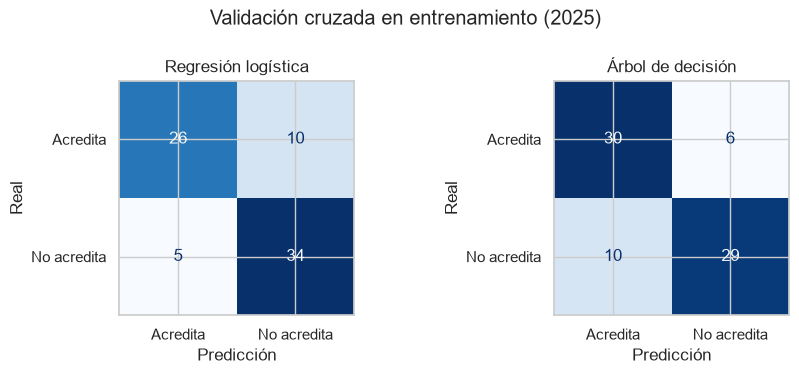

In [8]:
# Matrices de confusión con las predicciones de validación cruzada (cada registro predicho por un modelo que no lo vio)
fig, ejes = plt.subplots(1, 2, figsize=(9, 3.8))
pred_cv = {}
for ax, (nombre, grid) in zip(ejes, [("Regresión logística", grid_lr), ("Árbol de decisión", grid_dt)]):
    pred_cv[nombre] = cross_val_predict(grid.best_estimator_, X_train, y_train, groups=g_train, cv=cv)
    ConfusionMatrixDisplay(confusion_matrix(y_train, pred_cv[nombre]),
                           display_labels=["Acredita", "No acredita"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nombre); ax.set_xlabel("Predicción"); ax.set_ylabel("Real")
plt.suptitle("Validación cruzada en entrenamiento (2025)")
plt.tight_layout(); plt.savefig(FIGURAS / "confusion_validacion.png", dpi=120); plt.show()

### Elección del modelo

Se elige el modelo con **mayor F1 medio en validación cruzada** (criterio fijado antes de mirar la prueba). El otro modelo se conserva para comparar e interpretar.

In [9]:
f1_lr, f1_dt = grid_lr.best_score_, grid_dt.best_score_
elegido_nombre = "Regresión logística" if f1_lr >= f1_dt else "Árbol de decisión"
elegido = grid_lr.best_estimator_ if elegido_nombre == "Regresión logística" else grid_dt.best_estimator_
print(f"F1 en validación -> regresión logística: {f1_lr:.2f} | árbol: {f1_dt:.2f}. Modelo elegido: {elegido_nombre}.")

F1 en validación -> regresión logística: 0.82 | árbol: 0.78. Modelo elegido: Regresión logística.


## 8. Evaluación final en la prueba (1° cuatrimestre 2026)

El modelo elegido y entrenado se aplica **una sola vez** a la prueba. Con solo 4 casos de "no acredita", cada acierto o error cambia el recall en 25 puntos: los resultados son orientativos.

                 precision    recall  f1-score   support

   Acredita (0)       0.88      0.83      0.86        18
No acredita (1)       0.40      0.50      0.44         4

       accuracy                           0.77        22
      macro avg       0.64      0.67      0.65        22
   weighted avg       0.79      0.77      0.78        22

ROC AUC: 0.78


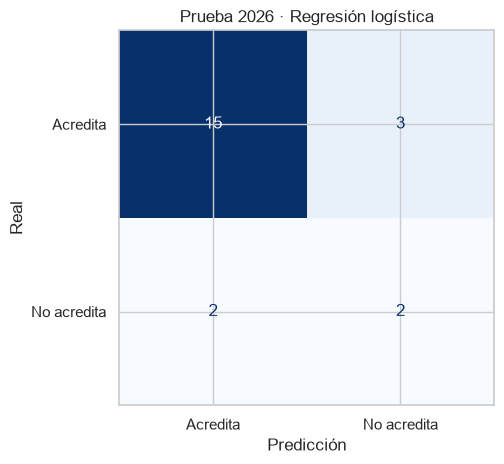

In [10]:
prob_test = elegido.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= 0.5).astype(int)
print(classification_report(y_test, pred_test, target_names=["Acredita (0)", "No acredita (1)"], zero_division=0))
print("ROC AUC:", round(roc_auc_score(y_test, prob_test), 2) if y_test.nunique() > 1 else "no calculable")

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_test), display_labels=["Acredita", "No acredita"]) \
    .plot(colorbar=False, cmap="Blues")
plt.title(f"Prueba 2026 · {elegido_nombre}"); plt.xlabel("Predicción"); plt.ylabel("Real")
plt.tight_layout(); plt.savefig(FIGURAS / "confusion_prueba.png", dpi=120); plt.show()

In [11]:
# Como referencia, el otro modelo en la misma prueba (no se usa para elegir)
otro_nombre, otro = (("Árbol de decisión", grid_dt.best_estimator_) if elegido_nombre == "Regresión logística"
                     else ("Regresión logística", grid_lr.best_estimator_))
p = otro.predict(X_test)
print(f"{otro_nombre} en prueba -> precision: {precision_score(y_test, p, zero_division=0):.2f} | "
      f"recall: {recall_score(y_test, p, zero_division=0):.2f} | F1: {f1_score(y_test, p, zero_division=0):.2f}")

Árbol de decisión en prueba -> precision: 0.40 | recall: 0.50 | F1: 0.44


## 9. Elección del umbral

Por defecto, el modelo marca "en riesgo" a quien tiene probabilidad mayor o igual a 0,5. Bajar el umbral detecta más estudiantes en riesgo (más recall) a costa de más falsas alarmas (menos precision). Como el objetivo es acompañar, perder a alguien en riesgo suele ser más costoso que conversar con alguien que no lo necesitaba. La elección del umbral se hace **con la validación cruzada del entrenamiento**, no con la prueba.

In [12]:
prob_cv = cross_val_predict(elegido, X_train, y_train, groups=g_train, cv=cv, method="predict_proba")[:, 1]
filas = []
for u in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (prob_cv >= u).astype(int)
    filas.append({"umbral": u, "marcados en riesgo": int(p.sum()),
                  "precision": round(precision_score(y_train, p, zero_division=0), 2),
                  "recall": round(recall_score(y_train, p, zero_division=0), 2),
                  "f1": round(f1_score(y_train, p, zero_division=0), 2)})
display(pd.DataFrame(filas).set_index("umbral"))

,marcados en riesgo,precision,recall,f1
umbral,,,,
0.3,75,0.52,1.00,0.68
0.4,67,0.57,0.97,0.72
0.5,44,0.77,0.87,0.82
0.6,18,0.83,0.38,0.53
0.7,1,1.00,0.03,0.05


## 10. Interpretación del modelo

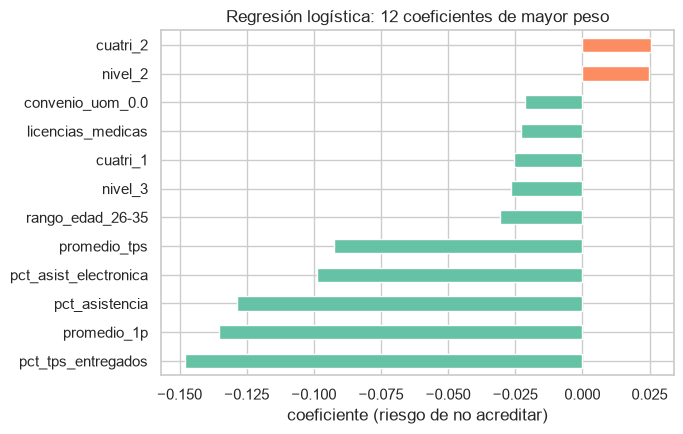

,coeficiente
pct_tps_entregados,-0.148
promedio_1p,-0.135
pct_asistencia,-0.129
pct_asist_electronica,-0.099
promedio_tps,-0.093
rango_edad_26-35,-0.031
nivel_3,-0.027
cuatri_2,0.025
cuatri_1,-0.025
nivel_2,0.025


In [13]:
# Regresión logística: coeficientes (variables escaladas, por eso son comparables entre sí).
# Positivo = aumenta el riesgo de no acreditar; negativo = lo disminuye.
lr = grid_lr.best_estimator_
coef = pd.Series(lr.named_steps["modelo"].coef_[0], index=lr.named_steps["prep"].get_feature_names_out())
coef.index = coef.index.str.replace("num__", "").str.replace("cat__", "")
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
ax = top.sort_values().plot(kind="barh", color=np.where(top.sort_values() > 0, "#fc8d62", "#66c2a5"), figsize=(7, 4.5))
ax.set_title("Regresión logística: 12 coeficientes de mayor peso"); ax.set_xlabel("coeficiente (riesgo de no acreditar)")
plt.tight_layout(); plt.savefig(FIGURAS / "coeficientes_logistica.png", dpi=120); plt.show()
display(top.round(3).to_frame("coeficiente"))

|--- promedio_1p <= 0.23
|   |--- pct_asistencia <= 0.70
|   |   |--- promedio_tps <= 0.57
|   |   |   |--- class: 1
|   |   |--- promedio_tps >  0.57
|   |   |   |--- class: 0
|   |--- pct_asistencia >  0.70
|   |   |--- pct_asist_electronica <= 1.23
|   |   |   |--- class: 0
|   |   |--- pct_asist_electronica >  1.23
|   |   |   |--- class: 1
|--- promedio_1p >  0.23
|   |--- turno_laboral_Tarde <= 0.50
|   |   |--- class: 0
|   |--- turno_laboral_Tarde >  0.50
|   |   |--- class: 0



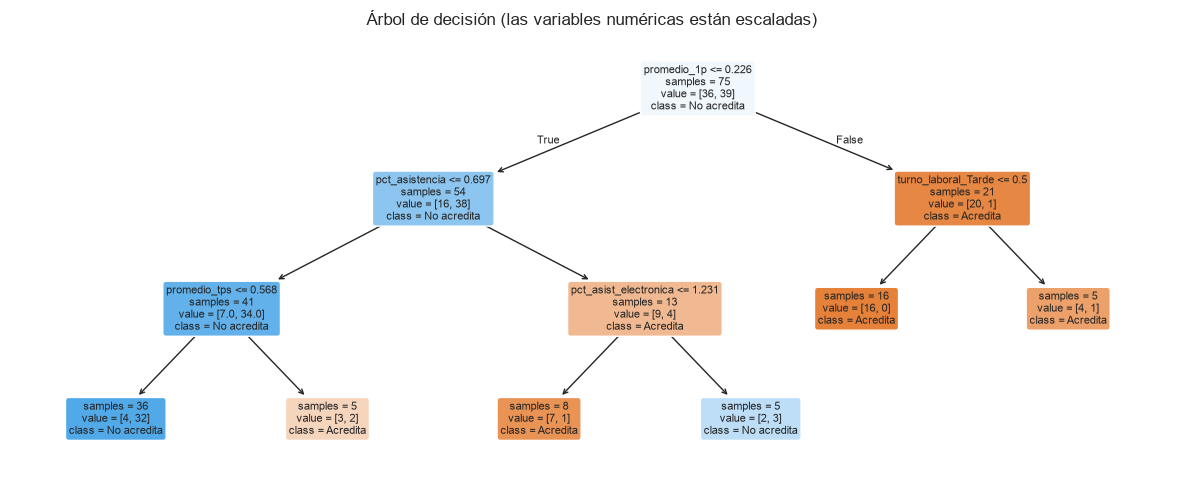

In [14]:
# Árbol de decisión: reglas
dt = grid_dt.best_estimator_
nombres = [n.replace("num__", "").replace("cat__", "") for n in dt.named_steps["prep"].get_feature_names_out()]
print(export_text(dt.named_steps["modelo"], feature_names=nombres, decimals=2))
plt.figure(figsize=(12, 5))
plot_tree(dt.named_steps["modelo"], feature_names=nombres, class_names=["Acredita", "No acredita"],
          filled=True, rounded=True, fontsize=8, impurity=False)
plt.title("Árbol de decisión (las variables numéricas están escaladas)")
plt.tight_layout(); plt.savefig(FIGURAS / "arbol_decision.png", dpi=120); plt.show()

Las variables numéricas del árbol están **escaladas** (media 0, desvío 1). Para leer un umbral en su escala original se puede convertir con la media y el desvío del entrenamiento:

In [15]:
escalador = dt.named_steps["prep"].named_transformers_["num"].named_steps["escalar"]
pd.DataFrame({"media": escalador.mean_, "desvío": escalador.scale_}, index=num_vars).round(3)

,media,desvío
clases_dictadas_corte,10.347,3.431
pct_asistencia,0.585,0.256
pct_asist_electronica,0.601,0.257
pct_ausente_con_aviso,0.070,0.093
licencias_medicas,0.147,0.667
pct_tps_entregados,0.366,0.361
promedio_tps,6.286,3.436
promedio_1p,6.757,1.446
materias_1p_menor6,0.640,0.919


## 11. Desempeño por grupos

Revisamos que el modelo no funcione peor para un grupo. Con las predicciones de validación cruzada se compara el recall (proporción de estudiantes en riesgo detectados) según sexo y grupo horario. Los grupos son chicos, así que solo permite detectar diferencias muy grandes.

In [16]:
pred_elegido_cv = (prob_cv >= 0.5).astype(int)
for var in ["sexo", "grupo"]:
    filas = []
    for valor, idx in train.groupby(train[var].fillna("Sin dato")).groups.items():
        yt, yp = y_train.loc[idx], pd.Series(pred_elegido_cv, index=y_train.index).loc[idx]
        filas.append({var: valor, "registros": len(idx), "no acreditan": int(yt.sum()),
                      "recall": round(recall_score(yt, yp, zero_division=0), 2) if yt.sum() else None})
    display(pd.DataFrame(filas).set_index(var))

,registros,no acreditan,recall
sexo,,,
Femenino,18,7,1.00
Masculino,54,29,0.83
Sin dato,3,3,1.00


,registros,no acreditan,recall
grupo,,,
12:30,20,11,0.82
15:30,55,28,0.89


## 12. Contraste: ¿qué pasaba con las planillas finales?

En una versión anterior, los TPs y las 1° notas se tomaban de las planillas finales, que incluyen entregas y cambios posteriores al corte. Para mostrar el efecto de esa **fuga de datos**, se entrena el mismo modelo reemplazando esas variables por las de las planillas finales. Si el desempeño mejora, la mejora no es real: el modelo estaría usando información que no existía el día de la predicción.

In [17]:
archivo_final = DATOS / "notas_planilla_final_real.csv"
if archivo_final.exists():
    finales = pd.read_csv(archivo_final)
    cols_notas = ["pct_tps_entregados", "promedio_tps", "promedio_1p", "materias_1p_menor6"]
    train_fuga = train.drop(columns=cols_notas).merge(
        finales[["id_estudiante", "anio", "cuatri", "nivel"] + cols_notas],
        on=["id_estudiante", "anio", "cuatri", "nivel"], how="left")
    X_fuga = preparar(train_fuga)
    comparacion = []
    for nombre, X in [("Notas al corte (correcto)", X_train), ("Notas de la planilla final (con fuga)", X_fuga)]:
        r = cross_validate(elegido, X, y_train, groups=g_train, cv=cv, scoring=metricas)
        comparacion.append({"datos": nombre, **{m: round(r["test_" + m].mean(), 2) for m in metricas}})
    display(pd.DataFrame(comparacion).set_index("datos"))
else:
    print("No está disponible el archivo con las notas de las planillas finales (es privado).")

,precision,recall,f1,roc_auc
datos,,,,
Notas al corte (correcto),0.80,0.87,0.82,0.88
Notas de la planilla final (con fuga),0.88,0.90,0.89,0.93


## 13. Aplicación al nivel 4 en curso (2° cuatrimestre 2026)

El modelo elegido estima el riesgo de los estudiantes que cursan nivel 4 ahora, con la información al cierre parcial del 25/09/2026. Por privacidad, aquí se muestra solo el resumen; el listado ordenado por riesgo queda en la computadora de la coordinadora. Cuando se cierre el cuatrimestre (27/11/2026) se podrá comparar con el resultado real.

Con una regularización fuerte (`C` chico), las probabilidades de la regresión logística quedan concentradas cerca de 0,5: sirven más para **ordenar** a los estudiantes de mayor a menor riesgo que como probabilidades exactas.

In [18]:
if len(en_curso):
    prob_actual = elegido.predict_proba(preparar(en_curso))[:, 1]
    print(f"Estudiantes en curso: {len(en_curso)} | marcados en riesgo (probabilidad ≥ 0,5): {int((prob_actual >= 0.5).sum())}")
    print(f"Probabilidades estimadas: mínimo {prob_actual.min():.2f}, mediana {np.median(prob_actual):.2f}, máximo {prob_actual.max():.2f}")
    if origen == "real":
        en_curso.assign(prob_no_acreditar=prob_actual.round(3))[["id_estudiante", "grupo", "prob_no_acreditar"]] \
            .sort_values("prob_no_acreditar", ascending=False) \
            .to_csv(DATOS / "riesgo_nivel4_2026_PRIVADO.csv", index=False)
        print("Listado ordenado guardado en data/processed/riesgo_nivel4_2026_PRIVADO.csv (no se sube).")

Estudiantes en curso: 19 | marcados en riesgo (probabilidad ≥ 0,5): 3
Probabilidades estimadas: mínimo 0.27, mediana 0.36, máximo 0.69
Listado ordenado guardado en data/processed/riesgo_nivel4_2026_PRIVADO.csv (no se sube).


## 14. Conclusiones

### Reflexión final

Como conclusión, realizar este trabajo me ayudó no solo a entender la materia sino también a comprender todo el potencial de usar modelos de aprendizaje automático. Este trabajo lo realicé en base a mi experiencia real como coordinadora de este proyecto, por lo que yo tengo registro de los estudiantes que están en riesgo actualmente. Pude constatar, a través de los modelos, que el resultado al cual arribé se corresponde con la realidad, lo cual terminaré de comprobar al cierre del cuatrimestre con los resultados finales. En este momento la matrícula es reducida, por lo cual el hacer el seguimiento no me representa un problema, pero en otros momentos en los que hemos tenido grupos de más de 200 estudiantes tener conocimientos sobre machine learning puede ayudar mucho a la tarea pedagógica.

Considero que se cumplió el objetivo de poder detectar a los estudiantes con un mayor riesgo de no acreditar, con la detección temprana al cierre de la 1° nota parcial, lo que me podría permitir emplear estrategias acordes a ello para revertir esa situación. Creo fundamental aclarar que este trabajo tiene un fin meramente pedagógico para conocer los estudiantes con un mayor riesgo de no acreditación haciendo un uso responsable de la información que el modelo proporciona, por lo tanto no fue creado para poner etiquetas o 
para influir en decisiones ajenas al ámbito escolar, por lo que el dataset con los datos reales solo estará al resguardo de la coordinadora y solo será usado con fines pedagógicos.

También pude entender algo que ya conocía intuitivamente: cuáles son las variables que más "pesan" para que un estudiante tenga un mayor riesgo de no acreditar: en la sección 10 pude observar que las variables con mayor peso estaban relacionadas a aspectos académicos: los estudiantes que más trabajos prácticos presentan son los que tienen menor riesgo de no acreditar, lo mismo sucede con quienes tienen un mejor promedio de notas en el 1° cierre parcial y quienes tienen un mayor porcentaje de asistencia, mientras que otras variables fueron las que tuvieron menos "peso" como por ejemplo si tuvieron licencias médicas o si están dentro del convenio con la UOM (relacionada al puesto laboral). Otro dato importante es que no se observa que el modelo funcione peor para algún grupo de personas en particular, ni con respecto al sexo ni tampoco al horario de cursada, teniendo en cuenta que son pocos datos para poder asegurarlo.

Una consideración que creo importante es que la matrícula del año 2025 era mayor, y además se trataba de distintos niveles (1° cuatrimestre nivel 1 y 3, 2° cuatrimestre nivel 2 y 4, mientras que en 2026 en el 1° cuatrimestre solo se cursó nivel 3 y actualmente en el 2° cuatrimestre se cursa solo nivel 4): creo que vale la pena diferenciar y profundizar en lo que pasa en cada uno de los niveles, antes de realizar este trabajo yo tenía algunas hipótesis que pude contrastar por medio de este trabajo: suponía, por ejemplo, que tendría más peso para el estudiante saber que está por concluir sus estudios en nivel 4, o una mayor probabilidad de que no acrediten en niveles tempranos donde la meta parecería lejana. Los datos de 2025 sugieren lo siguiente:

| Nivel | Registros | No acreditó |
|---|---|---|
| 1 | 23 | 35 % |
| 2 | 18 | 39 % |
| 3 | 34 | 44 % |
| 4 | 24 | 54 % |

Es decir, que el mayor porcentaje de no acreditación se dio en el nivel 4, mientras que al contrario en el nivel 1 fue el porcentaje menor. Como ya he mencionado, son grupos pequeños por lo cual no podría generalizar ni afirmar que esto sea un comportamiento común, podría ser interesante realizar este estudio con las cohortes de 2022 a 2024.

Entre las limitaciones que encontré al realizar este trabajo, puedo observar que en la prueba del 1° cuatrimestre 2026 el modelo detectó solo a 2 de 4 estudiantes que no acreditaron, lo cual es solo la mitad, entiendo que esto sucedió porque son muestras pequeñas y un solo estudiante representa al 25% de la muestra, lo cual hace que la variación sea grande. 

Otro aspecto que me llamó la atención es que el modelo ordenó a los estudiantes de mayor a menor riesgo, y en el puesto n° 8 se encontraba un estudiante que tuvo un muy buen desempeño en el último tiempo y de hecho ya no debe asistir a algunas materias por tenerlas aprobadas, pero también recordé que al principio del cuatrimestre acumuló varias inasistencias, por lo que esa predicción la entiendo como una mirada a una "foto vieja", el modelo solo puede saber lo que pasó hasta el 25/9 que fue la fecha del corte, lo que pasó de esa fecha en adelante se podrá ver reflejado luego del 2° cierre de notas del 27/11 y en las notas finales, que seguramente posicionarán distinto a ese estudiante en particular. Es importante aclarar que el modelo no lo marcaba como un estudiante en riesgo, solo que me llamó la atención que estuviera más arriba en la lista en comparación con otros estudiantes.

### Resultados principales

- **Validación cruzada (entrenamiento 2025):** la regresión logística detectó al 87 % de quienes no acreditaron (recall 0,87), con precision 0,80, F1 0,82 y ROC AUC 0,88. El árbol de decisión logró F1 0,78 y AUC 0,79. Ambos superan claramente al modelo de referencia al azar (F1 0,51, AUC 0,52).
- **Prueba (1° cuatrimestre 2026):** el modelo detectó 2 de los 4 estudiantes que no acreditaron (recall 0,50) y marcó 3 falsas alarmas (precision 0,40); ROC AUC 0,78. Con solo 4 casos positivos estos números son muy inestables. La cohorte 2026 tuvo además mucha menos no acreditación (18 %) que 2025 (52 %).
- **Variables más importantes:** en la regresión logística, el porcentaje de TPs entregados, el promedio de la 1° nota y la asistencia al corte (a más de cada una, menos riesgo). El perfil laboral y personal casi no pesa.
- **Regla principal del árbol** (traducida a la escala original): promedio de 1° nota de 7,1 o menos, asistencia de 76 % o menos y promedio de TPs de 8,2 o menos (incluye 0 si no entregó) → no acredita.
- **Umbral:** con la validación cruzada, 0,5 da el mejor equilibrio; bajarlo a 0,4 detecta al 97 % pero marca a casi todos (precision 0,57).
- **Por grupos:** el recall en validación fue de 1,00 en mujeres y 0,83 en varones, y de 0,82 y 0,89 en los grupos de 12:30 y 15:30. No aparece un grupo claramente perjudicado, aunque los grupos son chicos.
- **Fuga de datos:** con las notas de las planillas finales el modelo parecía mejor (F1 0,89 y AUC 0,93 contra 0,82 y 0,88), pero esa mejora es engañosa: usa información que no existía el día del corte.
- **Nivel 4 en curso:** el modelo marca a 3 de 19 estudiantes con probabilidad de 0,5 o más. Se podrá verificar al cierre del 27/11/2026.
- **Límites:** pocos datos (75 registros de entrenamiento), solo dos años, probabilidades poco calibradas por la regularización fuerte, y el modelo es una herramienta de alerta para acompañar, no para etiquetar.